# One photo at a time: the whole pipeline as it will run in flight

`single_photo_pipeline.py` (next to this notebook) holds the pipeline behind one call, `pipeline.run(photo, prior)`. This notebook does what a flight would do:

1. **Set up once** for the data set we care about: photos and camera, the map at all zoom levels, the feature families, the trained fusion model, the keypoint matcher, the DINO network. This is slow and happens before the first photo.
2. **Evaluation loop:** give the pipeline **one photo at a time**. It never sees the true position. After each answer we compare it with the truth, and we keep the time of every stage.

What you get: the contest score, the share answered, the error, the wrong answers (−20 points), how long each stage takes, and which photos are slow or wrong.

Timing is for **this computer**. The target hardware is slower (patch 0.5.5 assumes about 30 s per photo on the Orin at 15 W), so use the numbers for comparing stages and spotting slow photos, not as flight timing.

With `USE_HEADING_QUERIES` on, each photo is drawn several times (yaw guesses and a larger scale) and every drawing goes through the whole pipeline; the answer is chosen among all the candidates. Measured on 273 development photos: 41.3 -> 49.5 of 60 (see `tests/Heading_Queries/`).

# Part 1 · Settings

In [1]:
import os, sys, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

# ------------------------------------------------------------------ settings: change here, run again
DATA = "official"           # "official" (d1 photos; map from src/header/map_source.py: the new two-scene base map) or "nudt" (Changsha test photos)
MAP = "new"                # base map of the official photos: "new" (both scenes), "new_931", "new_921" (one scene each) or "old" (small_sat_area). Ignored for DATA = "nudt"
MAP_MARGIN_M = None         # metres of new map kept around the photos (None = 6000 from src/header/map_source.py; 2500 builds a much smaller, faster map)
N_PHOTOS = 500              # photos loaded for the data set (spread over the flights)
N_EVAL = 100                # photos sent through the loop, one at a time
COARSE = "edge_zncc"        # "fused" (learned fusion of six maps) or "edge_zncc" (edges only). The heading queries were measured with edge_zncc
USE_SEMANTIC_LAYER = True   # DINO re-orders the K coarse places before the fine stage
K_PEAKS = 50                # K: places the coarse search returns (the shortlist the DINO layer looks at); with heading queries: per query
M_FINE = 10                 # M <= K: places sent to the fine stage (per query when heading queries are on; 10 was measured) (with the DINO layer: the top M after DINO; without it: the first M of the coarse order)
MATCHER = "loftr_minima"    # fine matcher: "lightglue" (SuperPoint + LightGlue), "loftr_minima" (LoFTR, MINIMA weights) or "roma_minima" (RoMa). LoFTR/RoMa inlier counts are in the hundreds/thousands, not tens: the 12-inlier bar and GAMMA/RESCUE below need retuning
MIN_INLIERS = 8             # answer bar: answer when the chosen place has at least this many inliers (None = 12 from settings; for LoFTR try 5 to 8)
RANSAC_PIXELS = None        # a match is an inlier when it is within this many pixels of the fitted transform (None = 3.0 from settings)
MATCHER_CONFIDENCE = 0.2    # LoFTR only: matches with a lower confidence are dropped before RANSAC (0.2 = kornia's default; 0.1 scored higher on the development photos but lets weak, possibly false matches through)
LOFTR_COARSE_THRESHOLD = 0.2   # LoFTR only: its own cut on the coarse match probability (None = 0.2)
LOFTR_BORDER_PX = 0            # LoFTR only: matches within this many pixels of the edge of the really photographed canvas area are dropped (0 = keep all)
LOFTR_MARGIN = 0               # LoFTR only: grey / map pixels added around the canvas and the map window before matching (a multiple of 4: 0, 8, 16 ...)
USE_SEMANTIC_DECISION = True    # the DINO score also takes part in choosing the answer
GAMMA = 1.0                     # choose by  inliers + GAMMA * (DINO z-score);  0 = inliers only
RESCUE_INLIERS = None           # e.g. 9: also answer with this many inliers (instead of 12) ...
RESCUE_Z = None                 # ... when the DINO z-score of the chosen place is at least this (e.g. 2.0)
DINO_WEIGHT = None              # DINO's weight when it re-orders the K shortlist: 0 = keep the coarse order, 100 = DINO decides (None = 100 from semantic_rerank/dino_rerank.py)
SCALE = None                    # photo-to-map projection: multiplies the flight height (None = 1.04 from settings.GEOMETRY); 0.9 to 1.1 is a sensible range
YAW_OFFSET = None               # degrees added to the photo's yaw (None = 180.0 from settings.GEOMETRY)
HEIGHT_OFFSET = None            # metres added to the flight height before SCALE (None = 0.0 from settings.GEOMETRY)
USE_HEADING_QUERIES = True      # draw the photo once for each (heading, scale) pair and choose the answer among all the candidates
HEADINGS = [-5.0, 0.0, 5.0]     # degrees added to the photo's yaw, one query each (must contain 0.0). Metadata yaw is a few degrees off for some photos
SCALE_FACTORS = [1.0, 1.05]     # the projection scale is multiplied by each of these (must contain 1.0). Queries per photo = headings x scales = 6
TIME_BUDGET_S = 15          # a photo slower than this is flagged (patch 0.5.5: about 30 s per photo on the Orin)
SEED = 958476
plt.rcParams["figure.dpi"] = 90

# Part 2 · Set up once

`SinglePhotoPipeline(...)` only stores the choices. `setup()` does the slow work for the data set. Nothing here depends on a single photo, so in flight it would run before the first photo arrives.

In [2]:
from single_photo_pipeline import SinglePhotoPipeline, STAGES      # first import: it saves the development-set settings before NUDT changes them
from heading_query_pipeline import HeadingQueryPipeline
from src.header.scoring import points_for_error, final_score

pipeline_settings = dict(semantic_layer=USE_SEMANTIC_LAYER, semantic_decision=USE_SEMANTIC_DECISION,
                               gamma=GAMMA, rescue_inliers=RESCUE_INLIERS, rescue_z=RESCUE_Z,
                               k_peaks=K_PEAKS, m_fine=M_FINE, matcher=MATCHER,
                               min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS, matcher_confidence=MATCHER_CONFIDENCE, satellite=MAP, map_margin_m=MAP_MARGIN_M, loftr_coarse_threshold=LOFTR_COARSE_THRESHOLD,
                               loftr_border_px=LOFTR_BORDER_PX, loftr_margin=LOFTR_MARGIN,
                               dino_weight=DINO_WEIGHT, geometry={k: v for k, v in dict(scale=SCALE, yaw_offset=YAW_OFFSET, height_offset=HEIGHT_OFFSET).items() if v is not None})
if USE_HEADING_QUERIES:
    pipeline = HeadingQueryPipeline(DATA, COARSE, headings=HEADINGS, scale_factors=SCALE_FACTORS, **pipeline_settings)
else:
    pipeline = SinglePhotoPipeline(DATA, COARSE, **pipeline_settings)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)

setup_table = pd.DataFrame({"seconds": pipeline.setup_seconds})
display(setup_table.round(2))

test_set = pipeline.test_set
camera = pipeline.camera
heights = np.array([item["rel_height"] for item in test_set.items])
print("%d photos, flight height %.0f to %.0f m" % (len(heights), heights.min(), heights.max()))

level 3: 0.85 m/pixel, picture 16378 x 16004, map coverage 100%
level 4: 1.20 m/pixel, picture 11581 x 11316, map coverage 100%
level 5: 1.70 m/pixel, picture 8189 x 8002, map coverage 100%
level 6: 2.40 m/pixel, picture 5790 x 5658, map coverage 100%
level 7: 3.39 m/pixel, picture 4094 x 4001, map coverage 100%
map store ready, took 128 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


setup done in 145.2 s
data: official | 379 photos available | zoom levels [3, 4, 5, 6, 7]
photos: official | map: new
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=50 -> M=10) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.20 | LoFTR coarse threshold 0.2, upscale 1.0 | border 0 px, margin 0 px
DINO order weight: 100.0 | projection overrides: none (settings.GEOMETRY)
device: cuda
queries per photo: 6 (headings [-5.0, 0.0, 5.0], scale factors [1.0, 1.05]); K and M are per query


,seconds
DINO encoder,1.82
"feature families (edge, MIND, learned)",0.00
fine matcher (LoFTR + MINIMA weights),0.39
map at all zoom levels + edge features,127.78
"photos, camera and map",15.23


379 photos, flight height 100 to 351 m


# Part 3 · Warm-up

The first call is slower than the later ones (GPU kernels are compiled, caches are filled). In flight this would be done on the ground, so one photo is run and its time is kept apart from the loop.

In [3]:
warm = pipeline.run(test_set.items[0], test_set.priors[0])
print("warm-up photo: %.1f s in total" % warm["total"])
print({label: round(warm["seconds"][label], 2) for label in STAGES})

warm-up photo: 6.7 s in total
{'render': 0.05, 'maps': 2.83, 'coarse': 0.01, 'semantic': 1.13, 'fine': 2.72, 'decision': 0.0}


# Part 4 · The evaluation loop: one photo in, one answer out

For each photo: `pipeline.run(photo, prior)`. The pipeline gets the photo record and the rough 5 km hint, **not** the truth. The truth is used here only to judge the answer: error in metres and in sigma, and the contest points (a skipped photo gets 0, a wrong answer −20).

In [4]:
rows = []
failures = []
loop_start = time.time()
count = min(N_EVAL, len(test_set.items))
for index in range(count):
    item = test_set.items[index]
    try:
        result = pipeline.run(item, test_set.priors[index])
    except Exception as error:
        failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
        continue

    truth_x, truth_y = test_set.truths[index]
    error_m = math.hypot(result["x"] - truth_x, result["y"] - truth_y)
    earned = points_for_error(error_m, item["rel_height"], camera.fx)
    if result["answered"]:
        points = earned
    else:
        points = 0

    answer_lat, answer_lon = pipeline.satellite_map.metres_to_gps(result["x"], result["y"])      # the answer (metres on the map) as latitude, longitude
    row = dict(photo=index, true_lat=item["lat"], true_lon=item["lon"], lat=answer_lat, lon=answer_lon,
               height=item["rel_height"], level=result["level"], sigma_m=test_set.sigmas[index],
               error_m=error_m, error_sigma=error_m / test_set.sigmas[index], answered=result["answered"],
               inliers=result["inliers"], chosen=result["chosen"], z_chosen=result["z_chosen"], points=points)
    if USE_HEADING_QUERIES:
        chosen_query = result["queries"][result["owner"][result["chosen"]]]
        row["chosen_heading"] = chosen_query["heading"]
        row["chosen_scale"] = chosen_query["scale_factor"]
    for label in STAGES:
        row["t_" + label] = result["seconds"][label]
    row["t_total"] = result["total"]
    row["gpu_peak_mb"] = result["gpu_peak_mb"]
    rows.append(row)

    if (index + 1) % 10 == 0:
        so_far = pd.DataFrame(rows)
        print("photo %3d/%d | score so far %.1f /60 | answered %.2f | mean %.1f s per photo | slowest %.1f s" % (
            index + 1, count, final_score(list(so_far["points"])), so_far["answered"].mean(), so_far["t_total"].mean(), so_far["t_total"].max()))

results = pd.DataFrame(rows)
print("%d photos done in %.0f s (%d failed)" % (len(results), time.time() - loop_start, len(failures)))

photo  10/100 | score so far 48.0 /60 | answered 0.80 | mean 4.7 s per photo | slowest 6.1 s
photo  20/100 | score so far 48.6 /60 | answered 0.85 | mean 4.4 s per photo | slowest 6.1 s
photo  30/100 | score so far 52.4 /60 | answered 0.90 | mean 4.3 s per photo | slowest 6.2 s
photo  40/100 | score so far 49.8 /60 | answered 0.85 | mean 4.4 s per photo | slowest 6.2 s
photo  50/100 | score so far 50.6 /60 | answered 0.86 | mean 4.3 s per photo | slowest 6.2 s
photo  60/100 | score so far 50.2 /60 | answered 0.85 | mean 4.4 s per photo | slowest 6.2 s
photo  70/100 | score so far 49.5 /60 | answered 0.84 | mean 4.4 s per photo | slowest 6.3 s
photo  80/100 | score so far 49.8 /60 | answered 0.85 | mean 4.4 s per photo | slowest 6.3 s
photo  90/100 | score so far 50.3 /60 | answered 0.86 | mean 4.4 s per photo | slowest 6.4 s
photo 100/100 | score so far 48.8 /60 | answered 0.83 | mean 4.4 s per photo | slowest 6.4 s
100 photos done in 439 s (0 failed)


## 4.1 True position against the answer

One row per photo: the true latitude and longitude (from the photo's metadata, never seen by the pipeline), the latitude and longitude the pipeline returned, the distance between them, and whether it answered (a skipped photo still shows its best guess, but scores 0).

In [5]:
positions = results[["photo", "true_lat", "true_lon", "lat", "lon", "error_m", "answered"]]

# as an array: one row per photo = [true_lat, true_lon, returned_lat, returned_lon]
true_vs_returned = results[["true_lat", "true_lon", "lat", "lon"]].to_numpy()
np.set_printoptions(precision=6, suppress=True, linewidth=120)
print("true_vs_returned:", true_vs_returned.shape, "(photos, [true_lat, true_lon, returned_lat, returned_lon])")
print(true_vs_returned[:10])
display(positions.head(10).round(6))


true_vs_returned: (100, 4) (photos, [true_lat, true_lon, returned_lat, returned_lon])
[[19.124083 73.084061 19.1241   73.084078]
 [19.131329 73.083893 19.131344 73.083872]
 [19.127205 73.081482 19.127156 73.081522]
 [19.128729 73.080231 19.128748 73.080226]
 [19.122801 73.077271 19.122859 73.077309]
 [19.12833  73.087555 19.128367 73.087554]
 [19.127827 73.087448 19.127829 73.087474]
 [19.12674  73.077515 19.126756 73.077561]
 [19.133162 73.081566 19.13317  73.081569]
 [19.127726 73.091942 19.156445 73.049447]]


,photo,true_lat,true_lon,lat,lon,error_m,answered
0,0,19.124083,73.084061,19.124100,73.084078,2.585753,True
1,1,19.131329,73.083893,19.131344,73.083872,2.793342,True
2,2,19.127205,73.081482,19.127156,73.081522,6.888015,True
3,3,19.128729,73.080231,19.128748,73.080226,2.159833,True
4,4,19.122801,73.077271,19.122859,73.077309,7.519488,True
5,5,19.128330,73.087555,19.128367,73.087554,4.079359,True
6,6,19.127827,73.087448,19.127829,73.087474,2.722373,False
7,7,19.126740,73.077515,19.126756,73.077561,5.169199,True
8,8,19.133162,73.081566,19.133170,73.081569,0.972861,True
9,9,19.127726,73.091942,19.156445,73.049447,5486.246886,False


# Part 5 · What came out

## 5.1 Score and accuracy

In [6]:
summary = pd.DataFrame([{
    "photos": len(results),
    "score (/60)": final_score(list(results["points"])),
    "answered": results["answered"].mean(),
    "answer <= 1 sigma": (results["error_sigma"] <= 1).mean(),
    "answer <= 2 sigma": (results["error_sigma"] <= 2).mean(),
    "answer <= 4 sigma": (results["error_sigma"] <= 4).mean(),
    "median error (m)": results["error_m"].median(),
}])
display(summary.round(3))

earned_table = []
labels = [(10, "within 1 sigma (+10)"), (6, "within 2 sigma (+6)"), (3, "within 4 sigma (+3)"), (0, "answered, 4 to 8 sigma (0)"), (-20, "answered, wrong place (-20)")]
for value, label in labels:
    earned_table.append({"what the photo earned": label, "photos": int(((results["answered"]) & (results["points"] == value)).sum())})
earned_table.append({"what the photo earned": "skipped (0)", "photos": int((~results["answered"]).sum())})
display(pd.DataFrame(earned_table))
print("Of the skipped photos, %d had an answer within 4 sigma that was held back (fewer than the needed inliers)." % int(((~results["answered"]) & (results["error_sigma"] <= 4)).sum()))

,photos,score (/60),answered,answer <= 1 sigma,answer <= 2 sigma,answer <= 4 sigma,median error (m)
0,100,48.84,0.83,0.89,0.94,0.94,5.143


,what the photo earned,photos
0,within 1 sigma (+10),79
1,within 2 sigma (+6),4
2,within 4 sigma (+3),0
3,"answered, 4 to 8 sigma (0)",0
4,"answered, wrong place (-20)",0
5,skipped (0),17


Of the skipped photos, 11 had an answer within 4 sigma that was held back (fewer than the needed inliers).


## 5.2 Time: where it goes

,mean (s),median (s),95th percentile (s),max (s)
render,0.04,0.04,0.04,0.04
maps,1.19,1.19,2.88,2.98
coarse,0.00,0.01,0.01,0.01
semantic,0.66,0.65,0.74,0.75
fine,2.49,2.48,2.61,2.65
decision,0.00,0.00,0.00,0.00
total,4.37,4.34,6.16,6.37


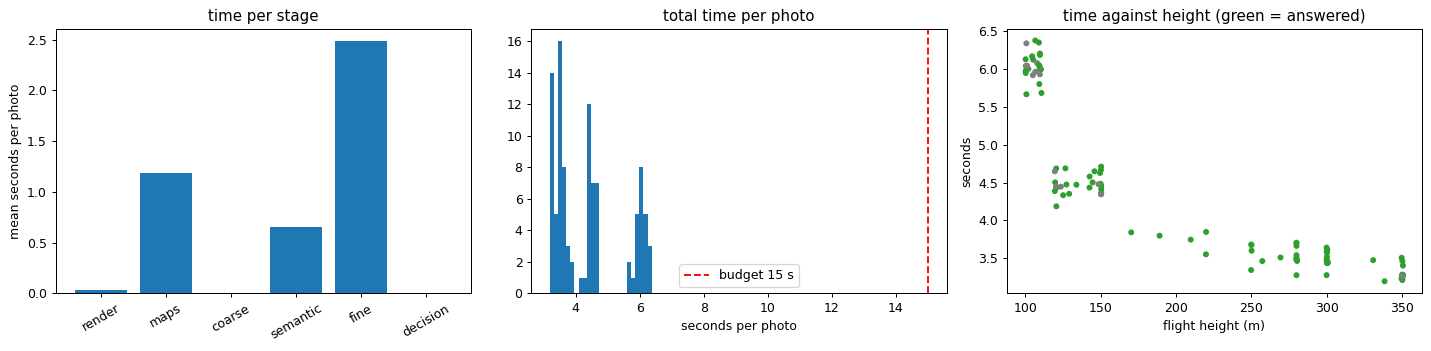

0 photos over the 15 s budget on this computer. GPU memory peak: 2925 MB


In [7]:
stage_columns = ["t_" + label for label in STAGES]
timing = results[stage_columns + ["t_total"]].describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]]
timing.index = [name[2:] for name in timing.index]
timing.columns = ["mean (s)", "median (s)", "95th percentile (s)", "max (s)"]
display(timing.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(STAGES, [results["t_" + label].mean() for label in STAGES])
axes[0].set_ylabel("mean seconds per photo")
axes[0].set_title("time per stage")
axes[0].tick_params(axis="x", rotation=30)
axes[1].hist(results["t_total"], bins=25)
axes[1].axvline(TIME_BUDGET_S, color="red", ls="--", label="budget %d s" % TIME_BUDGET_S)
axes[1].set_xlabel("seconds per photo")
axes[1].set_title("total time per photo")
axes[1].legend()
colours = ["tab:green" if answered else "tab:gray" for answered in results["answered"]]
axes[2].scatter(results["height"], results["t_total"], c=colours, s=14)
axes[2].set_xlabel("flight height (m)")
axes[2].set_ylabel("seconds")
axes[2].set_title("time against height (green = answered)")
plt.tight_layout()
plt.show()

over = (results["t_total"] > TIME_BUDGET_S).sum()
print("%d photos over the %d s budget on this computer. GPU memory peak: %.0f MB" % (over, TIME_BUDGET_S, results["gpu_peak_mb"].max()))

## 5.3 Errors and the photos to look at

The slowest photos and the wrong answers. Open one in `Pipeline_Visual_Check.ipynb` (set `PHOTO`) to see why.

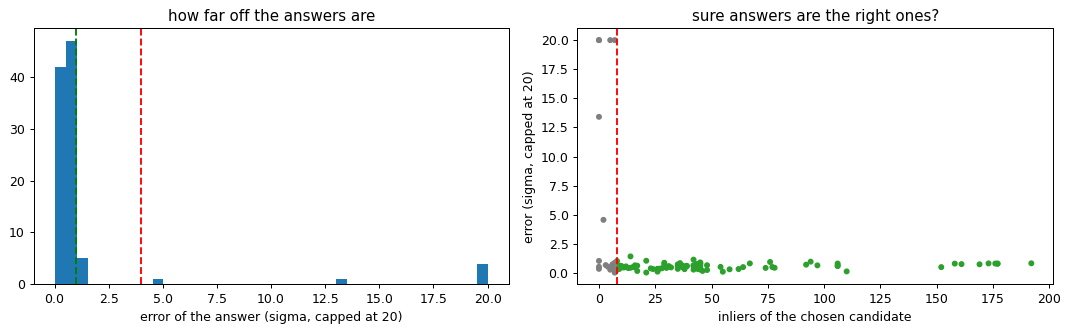

slowest photos


,photo,height,level,error_sigma,answered,inliers,points,t_total
81,81,106.5,3,0.57,True,39,10,6.37
91,91,108.9,3,0.36,True,26,10,6.34
61,61,100.6,3,0.35,False,7,0,6.33
51,51,109.6,3,0.66,True,16,10,6.20
37,37,109.6,3,0.66,True,42,10,6.18


wrong answers that cost 20 points


,photo,height,level,error_sigma,answered,inliers,points,t_total


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(results["error_sigma"].clip(upper=20), bins=40)
axes[0].axvline(1, color="green", ls="--")
axes[0].axvline(4, color="red", ls="--")
axes[0].set_xlabel("error of the answer (sigma, capped at 20)")
axes[0].set_title("how far off the answers are")
axes[1].scatter(results["inliers"], results["error_sigma"].clip(upper=20), c=colours, s=14)
axes[1].axvline(pipeline.min_inliers, color="red", ls="--")
axes[1].set_xlabel("inliers of the chosen candidate")
axes[1].set_ylabel("error (sigma, capped at 20)")
axes[1].set_title("sure answers are the right ones?")
plt.tight_layout()
plt.show()

columns = ["photo", "height", "level", "error_sigma", "answered", "inliers", "points", "t_total"]
print("slowest photos")
display(results.sort_values("t_total", ascending=False)[columns].head(5).round(2))
print("wrong answers that cost 20 points")
display(results[results["points"] < 0][columns].round(2))
if len(failures) > 0:
    print("photos that raised an error")
    display(pd.DataFrame(failures))

## 5.4 Save the per-photo table

In [9]:
out_dir = ROOT / "tests" / "Single_Image_Run"
out_dir.mkdir(parents=True, exist_ok=True)
file_name = "per_photo_%s_%s_%s_layer%d_K%d_M%d_%s.csv" % (DATA, MAP if DATA == "official" else "nudtmap", COARSE, int(USE_SEMANTIC_LAYER), K_PEAKS, M_FINE, MATCHER)
if USE_HEADING_QUERIES:
    file_name = file_name.replace(".csv", "_q%d.csv" % len(pipeline.queries))
results.to_csv(out_dir / file_name, index=False)
print("saved", out_dir / file_name)

saved /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Single_Image_Run/per_photo_official_new_edge_zncc_layer1_K50_M10_loftr_minima_q6.csv


**Caveats.** Photos and map are from the development set; the real evaluation uses a different map. With `N_EVAL` near 100 the score has a wide interval (several points out of 60), so compare settings on the same photos, not across runs. The learned fusion was trained on the NUDT (Changsha) photos, so the official set tests it on another city. To compare two settings fairly (for example `USE_SEMANTIC_LAYER` on and off), run this notebook twice with the same `SEED` and `N_EVAL` and compare the two saved tables photo by photo.